In [62]:
# Importar librerías necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score

##### 1. Cargar el dataset de cáncer de mama y convertirlo en un DataFrame

In [64]:
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target  # Añadir la columna target

In [66]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [68]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [70]:
df['target'].value_counts(dropna = False)

target
1    357
0    212
Name: count, dtype: int64

##### Separar las características (X) y la variable objetivo (y)

In [72]:
X = df.drop('target', axis=1)
y = df['target']

##### 2. Dividir los datos en conjunto de entrenamiento y prueba

In [74]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

##### 3. Estandarizamos los datos (es importante para muchos modelos, incluyendo la regresión logística)

In [76]:
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

##### 4. Entrenar un modelo de Regresión Logística

In [78]:
model = LogisticRegression()
model.fit(X_train_std, y_train)

LogisticRegression()

##### 5. Predecir las probabilidades para el conjunto de test (para clase 1)

In [80]:
# 5. Predecir las probabilidades para el conjunto de test (para clase 1)
yhat_roc = model.predict_proba(X_test_std)[:, 1]

##### 6. Calcular la curva ROC

In [82]:
# Falsos positivos -> false_positive
# Verdaderos positivos -> true_positive
# threshold -> umbral de decisión
false_positive, true_positive, threshold = roc_curve(y_test, yhat_roc)

##### 7. Calcular el AUC

In [84]:
auc = roc_auc_score(y_test, yhat_roc)
print(f"AUC: {auc:.3f}")

AUC: 0.998


##### 8. Graficar la curva ROC

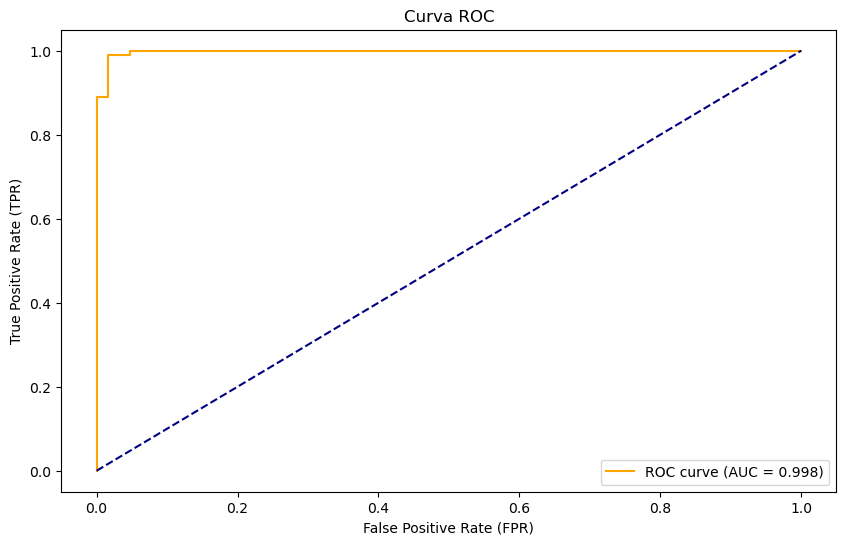

In [88]:
plt.figure()
plt.plot(false_positive, true_positive, color='orange', label=f'ROC curve (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')  # Línea de referencia
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Curva ROC')
plt.legend(loc="lower right")
plt.show()

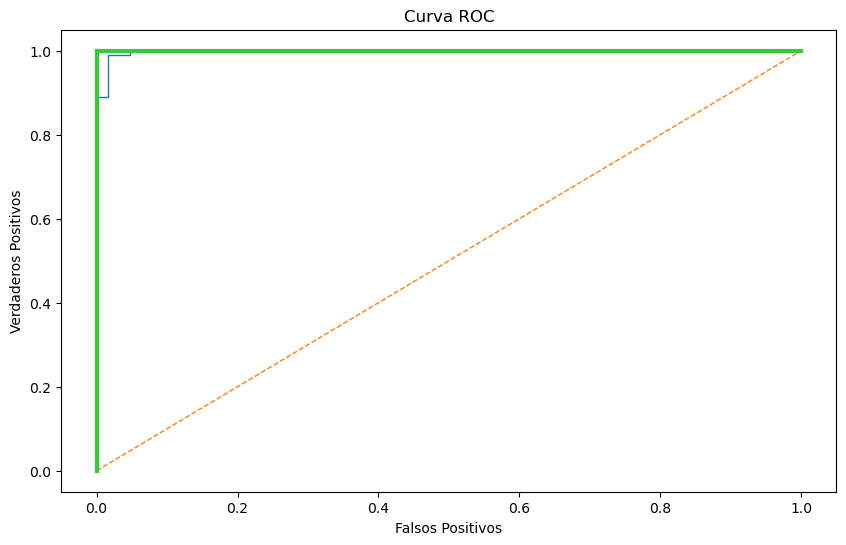

In [90]:
# Procedemos a dibujar el grafico correspondiente de la curva ROC
plt.rcParams['figure.figsize'] = (10, 6)
plt.title('Curva ROC') 
plt.plot(false_positive, true_positive, lw=1) 
plt.plot([0, 1], ls="--", lw=1) 
plt.plot([0, 0], [1, 0] , c='limegreen', lw=3), 
plt.plot([1, 1] , c='limegreen', lw=3) 
plt.ylabel('Verdaderos Positivos') 
plt.xlabel('Falsos Positivos');

##### 15 personas mas probables en tener cancer maligno

1. Obtener las probabilidades de que cada persona en el conjunto de prueba tenga cáncer maligno

In [26]:
# Esto ya se ha realizado con el siguiente codigo
# yhat_roc = model.predict_proba(X_test_std)[:, 1]

2. Procedemos a extraer esas probabilidades, colocarlas en un DataFrame y ordenarlas de mayor a menor.

In [92]:
# Por lo cual extraemos las probabilidades y las colocamos en un DataFrame
df_probabilidad = pd.DataFrame({'probabilidad_maligno': yhat_roc,'true_label': y_test})


# Procedemos a ordenar las probabilidades de tener cancer maligno de mayor a menor
df_probabilidad_ordenado = df_probabilidad.sort_values(by = 'probabilidad_maligno', ascending = False)

3. Seleccionamos las 15 personas con las probabilidades mas altas

In [30]:
df_top_15 = df_probabilidad_ordenado.head(15)

In [31]:
df_top_15

,probabilidad_maligno,true_label
192,1.000000,1
101,0.999999,1
140,0.999998,1
63,0.999993,1
46,0.999990,1
556,0.999989,1
428,0.999979,1
145,0.999979,1
176,0.999974,1
60,0.999972,1
